# Libraries

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

 # Dataset load and preprocess

In [9]:
df = pd.read_csv('data.csv')
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df['diagnosis'] = df['diagnosis'].map({'M': 0, 'B': 1})

print(df.shape)
print(df.isnull().sum().sum(), 'missing values')
print(np.unique(df['diagnosis'], return_counts=True))

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

(569, 31)
0 missing values
(array([0, 1], dtype=int64), array([212, 357], dtype=int64))


# Data exploration

Shape: (569, 31)

First 5 rows:
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          0        17.99         10.38          122.80     1001.0   
1          0        20.57         17.77          132.90     1326.0   
2          0        19.69         21.25          130.00     1203.0   
3          0        11.42         20.38           77.58      386.1   
4          0        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0         0.2

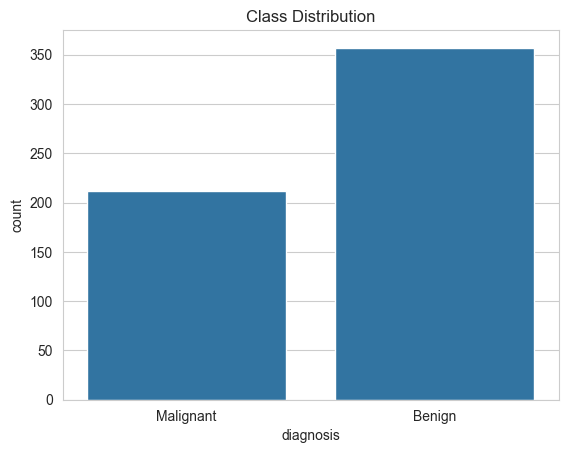

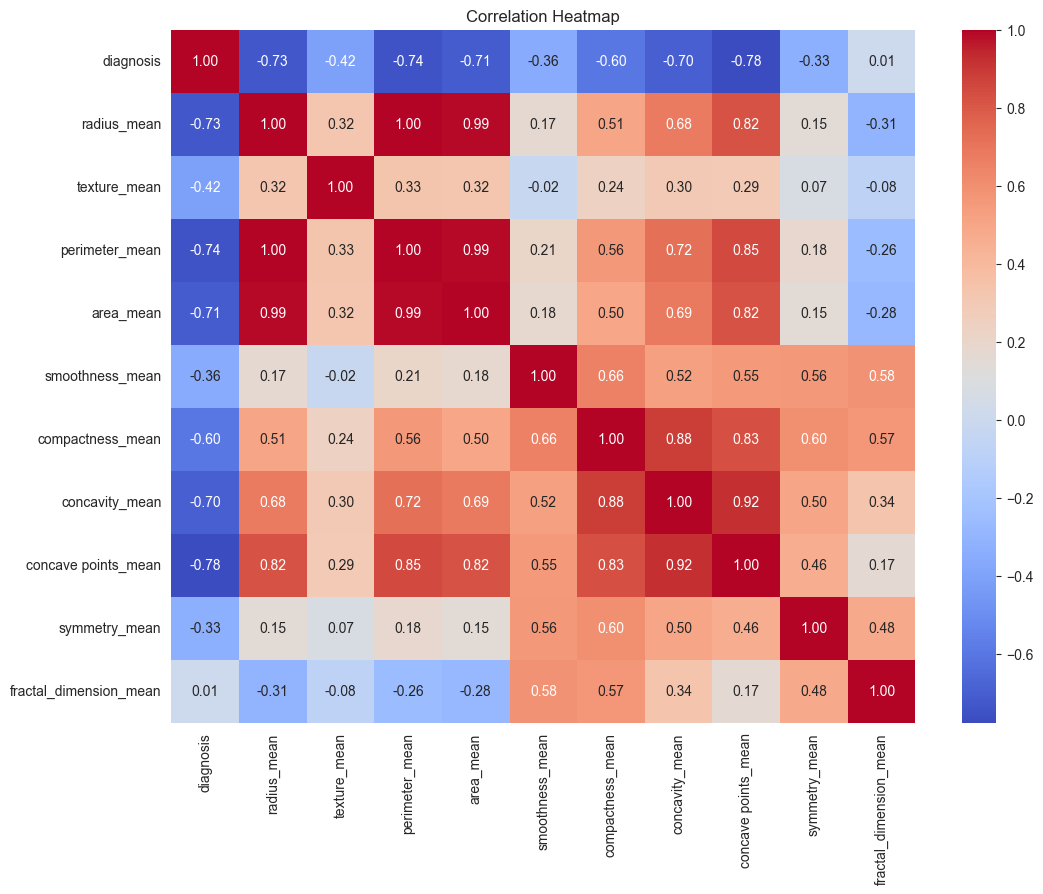

In [14]:

print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Info:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

print("\nStatistical Summary:")
print(df.describe())

print("\nClass Distribution (0 = Malignant, 1 = Benign):")
print(df['diagnosis'].value_counts())

sns.countplot(x='diagnosis', data=df)
plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.title('Class Distribution')
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df.iloc[:, :11].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# Models train

In [15]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_sc, y_train)
svm_pred = svm.predict(X_test_sc)

# Metrics

In [16]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'SVM'],
    'Accuracy': [accuracy_score(y_test, dt_pred), accuracy_score(y_test, svm_pred)],
    'Precision': [precision_score(y_test, dt_pred), precision_score(y_test, svm_pred)],
    'Recall': [recall_score(y_test, dt_pred), recall_score(y_test, svm_pred)],
    'F1-Score': [f1_score(y_test, dt_pred), f1_score(y_test, svm_pred)]
}).round(4)
results

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.9386,0.9577,0.9444,0.9510
1,SVM,0.9825,0.9861,0.9861,0.9861


# Confusion metrices

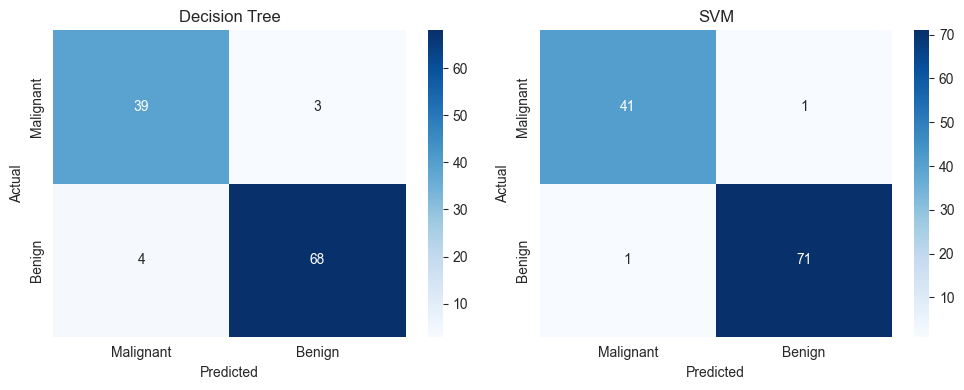

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, name in zip(axes, [dt_pred, svm_pred], ['Decision Tree', 'SVM']):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d',
                cmap='Blues', ax=ax,
                xticklabels=['Malignant', 'Benign'],
                yticklabels=['Malignant', 'Benign'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()